# TP 11 — CNN (réseau de neurones convolutif)
**Deep Learning · Images**


| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 79 | Convolution : un filtre [1 0 −1] détecte les bords d’une barre verticale (image 5×5) |
| Exemple 2 | 80 | Apprentissage : un filtre 2×2 apprend à reconnaître une barre verticale, comme le chiffre « 1 » (image 3×3, 3 epochs) |

Dans une image en niveaux de gris, chaque pixel est un nombre : ici **1 = noir**, **0 = blanc**.

**Objectifs** : programmer **en Python pur** la convolution, le pooling max, la rétropropagation vers le filtre et la mise à jour, et les appliquer aux exemples des diapos ; puis refaire le même calcul avec **Keras** (`Conv2D`, `GlobalMaxPooling2D`) et comparer les deux implémentations.

## Rappel de cours

- **Convolution** : un petit **filtre** (une grille de poids) glisse sur l’image. À chaque position, on multiplie case par case et on additionne : $\text{carte}(i,j) = \sum_{u,v} \text{pixel}(i+u, j+v)\times K(u,v)$. Le résultat est la **carte de caractéristiques** (*feature map*).
- Avec `padding="valid"` (pas de bord ajouté), une image $n\times n$ et un filtre $k\times k$ donnent une carte $(n-k+1)\times(n-k+1)$.
- **Pooling max** : on garde la plus grande valeur d’une zone ; ici on garde la plus grande valeur de toute la carte (*global max pooling*).
- **Ce que le CNN apprend : les valeurs des filtres.** On les corrige par rétropropagation, comme les poids d’un réseau.

---
# Partie A — Implémentation from scratch (Python pur)

## Exemple 1 : détecter les bords d’une barre verticale (diapo80)

Image 5×5 avec une barre verticale noire au milieu ; filtre 3×3 dont chaque ligne vaut [1 0 −1].

### Question 1 — Calculer la carte de caractéristiques
**Réponse.** Première case (3 premières colonnes) : sur chaque ligne $0\times 1 + 0\times 0 + 1\times(-1) = -1$, donc $-3$ sur 3 lignes. Fenêtre centrée sur la barre : $0\times 1 + 1\times 0 + 0\times(-1) = 0$. Dernière fenêtre : $1\times 1 + 0 + 0 = 1$ par ligne, donc $+3$.
La carte vaut $[-3 ; 0 ; 3]$ sur chaque ligne : le filtre réagit aux **bords** de la barre (−3 à gauche, +3 à droite).

In [ ]:
def convolution(image, filtre):
    n, k = len(image), len(filtre)    #nbre de lignes ds image n et filtre k
    taille = n - k + 1                                   # padding "valid"
    carte = []
    for i in range(taille):
        ligne = []
        for j in range(taille):
            s = sum(image[i + u][j + v] * filtre[u][v] for u in range(k) for v in range(k))
            ligne.append(s)
        carte.append(ligne)
    return carte

image5 = [[0, 0, 1, 0, 0] for _ in range(5)]
filtre_bord = [[1, 0, -1] for _ in range(3)]
carte5 = convolution(image5, filtre_bord)
for ligne in carte5:
    print(ligne)

[-3, 0, 3]
[-3, 0, 3]
[-3, 0, 3]


## Exemple 2 : apprendre un filtre 2×2

| Image 3×3 | Filtre de départ |
|---|---|
| $\begin{bmatrix}0&1&0\\0&1&0\\0&1&0\end{bmatrix}$ | $\begin{bmatrix}0{,}2&0{,}1\\0{,}2&0{,}1\end{bmatrix}$ |

L’image contient une barre verticale, donc $y = 1$. Règles de la diapo :
- carte 2×2 = convolution ; $m$ = max de la carte (pooling) ;
- sortie **fixée** (pour suivre le filtre seul) : $z = 3m - 2$ ; $p = \sigma(z)$ ; perte $= -\ln p$ ;
- gradient $= (p - y)\times 3$, reçu par les pixels de la **fenêtre gagnante** (celle qui a donné le max) ;
- filtre $:=$ filtre $- \eta\times(\text{gradient}\times\text{pixel})$ avec $\eta = 0{,}1$.

### Question 2 — Epoch 1
**Réponse.**
- Convolution : fenêtres colonnes 1-2 → $0{,}1 + 0{,}1 = 0{,}2$ ; colonnes 2-3 → $0{,}2 + 0{,}2 = 0{,}4$
- Pooling : $m = 0{,}4$ ; $z = 3\times 0{,}4 - 2 = -0{,}8$ ; $p = 0{,}31$ ; perte $= 1{,}17$
- Gradient : $(0{,}31 - 1)\times 3 = -2{,}07$ pour les pixels de la fenêtre gagnante
- Mise à jour : colonne gauche du filtre $0{,}2 - 0{,}1\times(-2{,}07)\times 1 = 0{,}41$ ; la colonne droite reste 0,1 (les pixels correspondants valent 0)

In [ ]:
import math
sigmoide = lambda z: 1 / (1 + math.exp(-z))
image3 = [[0, 1, 0] for _ in range(3)]

def epoch_cnn(filtre, image, y=1, eta=0.1):
    carte = convolution(image, filtre)
    m = max(max(l) for l in carte)   #max pooling
    i, j = next((i, j) for i in range(len(carte)) for j in range(len(carte)) if carte[i][j] == m)  # fenêtre gagnante (recherche de m)
    z = 3 * m - 2
    p = sigmoide(z)
    perte = -math.log(p)
    grad = (p - y) * 3                                   # dérivée de la perte par rapport à m
    nouveau = [[filtre[u][v] - eta * grad * image[i + u][j + v] for v in range(2)] for u in range(2)] #le gradient
    return carte, m, p, perte, grad, nouveau

filtre = [[0.2, 0.1], [0.2, 0.1]]
carte, m, p, perte, grad, filtre = epoch_cnn(filtre, image3)
print("Carte 2×2 :", carte)
print(f"Pooling max : m = {m}")
print(f"Sortie      : z = 3 × {m} − 2 = {3 * m - 2:.2f} ; p = σ(z) = {p:.4f} ; perte = −ln p = {perte:.4f}")
print(f"Gradient    : (p − 1) × 3 = {grad:.4f}")
print("Filtre après epoch 1 :", [[round(v, 4) for v in ligne] for ligne in filtre])

Carte 2×2 : [[0.2, 0.4], [0.2, 0.4]]
Pooling max : m = 0.4
Sortie      : z = 3 × 0.4 − 2 = -0.80 ; p = σ(z) = 0.3100 ; perte = −ln p = 1.1711
Gradient    : (p − 1) × 3 = -2.0699
Filtre après epoch 1 : [[0.407, 0.1], [0.407, 0.1]]


### Question 3 — Epochs 2 et 3
**Réponse.** La colonne gauche du filtre augmente : 0,2 → 0,41 → 0,52 → 0,60. Le filtre réagit de plus en plus fort à la barre : $m$ monte (0,4 → 0,81 → 1,05 → 1,19), $p$ monte (0,31 → 0,61 → 0,76 → 0,83) et la perte baisse (1,17 → 0,50 → 0,28 → 0,19).

In [ ]:
filtre = [[0.2, 0.1], [0.2, 0.1]]
historique_pur = []
for e in range(4):
    carte, m, p, perte, grad, nouveau = epoch_cnn(filtre, image3)
    historique_pur.append([ligne[:] for ligne in filtre])    #conserve les anciens poids pour pouvoir les visualiser
    print(f"Epoch {e} : K gauche = {filtre[0][0]:.3f} ; K droite = {filtre[0][1]:.3f} ; m = {m:.3f} ; p = {p:.3f} ; perte = {perte:.3f}")
    filtre = nouveau       #remplace l'ancien filtre par le nouveau

Epoch 0 : K gauche = 0.200 ; K droite = 0.100 ; m = 0.400 ; p = 0.310 ; perte = 1.171
Epoch 1 : K gauche = 0.407 ; K droite = 0.100 ; m = 0.814 ; p = 0.609 ; perte = 0.496
Epoch 2 : K gauche = 0.524 ; K droite = 0.100 ; m = 1.049 ; p = 0.759 ; perte = 0.276
Epoch 3 : K gauche = 0.597 ; K droite = 0.100 ; m = 1.193 ; p = 0.829 ; perte = 0.187


---
# Partie B — Les mêmes calculs avec Keras

### Question 4 — Exemple 1 avec `Conv2D`
**Réponse.** Une couche `Conv2D(filters=1, kernel_size=(3, 3), padding="valid", use_bias=False)` dont on impose le filtre. Les images Keras ont la forme (nombre d’images, hauteur, largeur, canaux).

In [ ]:
import numpy as np
import keras
from keras import layers

conv = layers.Conv2D(filters=1, kernel_size=(3, 3), padding="valid", use_bias=False)
X5 = np.array(image5, dtype="float32").reshape(1, 5, 5, 1)
conv.build(X5.shape)
conv.set_weights([np.array(filtre_bord, dtype="float32").reshape(3, 3, 1, 1)])   # (hauteur, largeur, canaux, filtres)
carte_keras = keras.ops.convert_to_numpy(conv(X5))[0, :, :, 0]
print(carte_keras)

[[-3.  0.  3.]
 [-3.  0.  3.]
 [-3.  0.  3.]]


### Question 5 — Exemple 2 : le modèle de la diapo 81, entraîné 3 epochs
**Réponse.** Modèle : `Conv2D(1, (2, 2), use_bias=False)` → `GlobalMaxPooling2D()` → `Dense(1, activation="sigmoid")`. La couche `Dense` est **fixée** à poids 3 et biais −2 (`trainable=False`), comme dans l’exemple de la Partie A : seul le filtre apprend. Optimiseur `SGD(learning_rate=0.1)`, perte `binary_crossentropy`.

In [ ]:
modele = keras.Sequential([keras.Input(shape=(3, 3, 1)),
                           layers.Conv2D(1, (2, 2), padding="valid", use_bias=False),
                           layers.GlobalMaxPooling2D(),
                           layers.Dense(1, activation="sigmoid", trainable=False)])
modele.layers[0].set_weights([np.array([[0.2, 0.1], [0.2, 0.1]], dtype="float32").reshape(2, 2, 1, 1)])
modele.layers[2].set_weights([np.array([[3.0]]), np.array([-2.0])])
modele.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1), loss="binary_crossentropy")

class HistoriqueFiltre(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.filtres = [self.model.layers[0].get_weights()[0][:, :, 0, 0].copy()]
    def on_epoch_end(self, epoch, logs=None):
        self.filtres.append(self.model.layers[0].get_weights()[0][:, :, 0, 0].copy())

X3 = np.array(image3, dtype="float32").reshape(1, 3, 3, 1)
hist = HistoriqueFiltre()
modele.fit(X3, np.array([[1.0]]), epochs=3, batch_size=1, verbose=0, callbacks=[hist])
for e, K in enumerate(hist.filtres):
    print(f"Keras epoch {e} : filtre = {[[round(float(v), 3) for v in ligne] for ligne in K]}")
print("p après 3 epochs :", round(float(modele.predict(X3, verbose=0)[0, 0]), 3))

Keras epoch 0 : filtre = [[0.2, 0.1], [0.2, 0.1]]
Keras epoch 1 : filtre = [[0.407, 0.1], [0.407, 0.1]]
Keras epoch 2 : filtre = [[0.524, 0.1], [0.524, 0.1]]
Keras epoch 3 : filtre = [[0.597, 0.1], [0.597, 0.1]]
p après 3 epochs : 0.829


---
# Partie C — Comparaison et validation
### Question 6 — Python pur et Keras apprennent-ils le même filtre ?

In [ ]:
import pandas as pd
print("Exemple 1 : carte Python pur =", carte5, "| carte Keras =", carte_keras.astype(int).tolist())
lignes = [(e, round(historique_pur[e][0][0], 4), round(float(hist.filtres[e][0, 0]), 4),
           round(historique_pur[e][0][1], 4), round(float(hist.filtres[e][0, 1]), 4)) for e in range(4)]
display(pd.DataFrame(lignes, columns=["Epoch", "K gauche Python pur", "K gauche Keras",
                                      "K droite Python pur", "K droite Keras"]))
assert np.allclose(carte_keras, carte5)
assert np.allclose([np.array(f) for f in historique_pur], hist.filtres, atol=1e-5)
print("Python pur = Keras : même carte de caractéristiques et même filtre appris à chaque epoch")

Exemple 1 : carte Python pur = [[-3, 0, 3], [-3, 0, 3], [-3, 0, 3]] | carte Keras = [[-3, 0, 3], [-3, 0, 3], [-3, 0, 3]]


,Epoch,K gauche Python pur,K gauche Keras,K droite Python pur,K droite Keras
0,0,0.2000,0.2000,0.1,0.1
1,1,0.4070,0.4070,0.1,0.1
2,2,0.5244,0.5244,0.1,0.1
3,3,0.5967,0.5967,0.1,0.1


✅ Python pur = Keras : même carte de caractéristiques et même filtre appris à chaque epoch


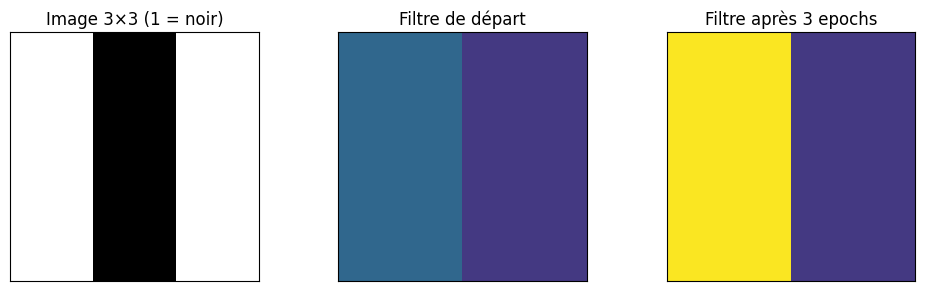

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].imshow(image3, cmap="Greys", vmin=0, vmax=1); ax[0].set_title("Image 3×3 (1 = noir)")
ax[1].imshow(historique_pur[0], cmap="viridis", vmin=0, vmax=0.6); ax[1].set_title("Filtre de départ")
ax[2].imshow(historique_pur[3], cmap="viridis", vmin=0, vmax=0.6); ax[2].set_title("Filtre après 3 epochs")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Conclusion

| Ce qu’on a comparé (Python pur ↔ Keras) | Résultat |
|---|---|


**À retenir**
- Un filtre est une petite grille de **poids appris** ; il détecte un motif là où la carte est forte.
- Le pooling max garde la réponse la plus forte : seule la **fenêtre gagnante** reçoit le gradient.
- Personne ne programme les filtres : la rétropropagation les ajuste, comme les poids d’un réseau dense.